In [33]:
import sys
import tensorflow as tf

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Python: /home/vivek_chauhan/tf-env/bin/python
TensorFlow: 2.18.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from pathlib import Path

SPLIT_DIR = Path("/mnt/c/liverCTSegmentation/outputs/splits")

train_csv = SPLIT_DIR / "train.csv"
val_csv = SPLIT_DIR / "validation.csv"
test_csv = SPLIT_DIR / "test.csv"

print("Train CSV exists:", train_csv.exists())
print("Validation CSV exists:", val_csv.exists())
print("Test CSV exists:", test_csv.exists())

Train CSV exists: True
Validation CSV exists: True
Test CSV exists: True


In [11]:
import pandas as pd

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)


def windows_to_wsl(path):
    path = str(path)

    # Convert Windows drive path to WSL path
    if path.startswith("C:\\"):
        path = "/mnt/c/" + path[3:].replace("\\", "/")

    elif path.startswith("C:/"):
        path = "/mnt/c/" + path[3:]

    return path


for df in [train_df, val_df, test_df]:
    df["image_path"] = df["image_path"].apply(windows_to_wsl)
    df["mask_path"] = df["mask_path"].apply(windows_to_wsl)


print("Image path:")
print(train_df.iloc[0]["image_path"])

print("\nMask path:")
print(train_df.iloc[0]["mask_path"])

print("\nTraining samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining volumes:", train_df["volume_id"].nunique())
print("Validation volumes:", val_df["volume_id"].nunique())
print("Testing volumes:", test_df["volume_id"].nunique())

Image path:
/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/Videos/archive (26)/last_dataset/images/Volume-001-000.png

Mask path:
/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/Videos/archive (26)/last_dataset/masks/Volume-001-000.png

Training samples: 39677
Validation samples: 8960
Testing samples: 10001

Training volumes: 91
Validation volumes: 19
Testing volumes: 21


In [12]:
print(repr(train_df.iloc[0]["image_path"]))
print(repr(train_df.iloc[0]["mask_path"]))

'/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/Videos/archive (26)/last_dataset/images/Volume-001-000.png'
'/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/Videos/archive (26)/last_dataset/masks/Volume-001-000.png'


In [13]:
from pathlib import Path

print("Image exists:", Path(train_df.iloc[0]["image_path"]).exists())
print("Mask exists :", Path(train_df.iloc[0]["mask_path"]).exists())

Image exists: True
Mask exists : True


Create the TensorFlow dataset


In [28]:
import tensorflow as tf

IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 16

AUTOTUNE = tf.data.AUTOTUNE


def load_image_mask(image_path, mask_path):

    # Read image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=1)

    # Read mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH],
        method=tf.image.ResizeMethod.BILINEAR
    )

    # Resize mask
    mask = tf.image.resize(
        mask,
        [IMG_HEIGHT, IMG_WIDTH],
        method=tf.image.ResizeMethod.NEAREST_NEIGHBOR
    )

    # Normalize image
    image = tf.cast(image, tf.float32) / 255.0

    # Convert mask to binary
    mask = tf.cast(mask > 127, tf.float32)

    return image, mask


def create_dataset(df, batch_size=16, shuffle=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            df["image_path"].values,
            df["mask_path"].values
        )
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image_mask,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

In [42]:
train_dataset = create_dataset(
    train_df,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_dataset = create_dataset(
    val_df,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_dataset = create_dataset(
    test_df,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Datasets created successfully.")

Datasets created successfully.


In [43]:
WINDOWS_DATASET = "C://Users//vivek chauhan//Desktop//dsa babbar//Videos//archive (26)//last_dataset"
WSL_DATASET = "/mnt/c/Users/vivek chauhan/Desktop/dsa babbar/Videos/archive (26)/last_dataset"

for df in [train_df, val_df, test_df]:
    df["image_path"] = df["image_path"].str.replace(
        WINDOWS_DATASET,
        WSL_DATASET,
        regex=False
    )
    df["mask_path"] = df["mask_path"].str.replace(
        WINDOWS_DATASET,
        WSL_DATASET,
        regex=False
    )

print("Image:", train_df.iloc[0]["image_path"])
print("Mask :", train_df.iloc[0]["mask_path"])

Image: /mnt/c/Users/vivek chauhan/Desktop/dsa babbar/Videos/archive (26)/last_dataset/images/Volume-001-000.png
Mask : /mnt/c/Users/vivek chauhan/Desktop/dsa babbar/Videos/archive (26)/last_dataset/masks/Volume-001-000.png


In [44]:
for images, masks in train_dataset.take(1):
    print("Images:", images.shape)
    print("Masks :", masks.shape)
    print("Image range:", tf.reduce_min(images).numpy(),
          "to", tf.reduce_max(images).numpy())
    print("Mask values:", tf.unique(tf.reshape(masks, [-1]))[0].numpy())

Images: (16, 128, 128, 1)
Masks : (16, 128, 128, 1)
Image range: 0.0 to 1.0
Mask values: [0. 1.]


# Verify one batch

In [45]:
images, masks = next(iter(train_dataset))

print("Image batch shape:", images.shape)
print("Mask batch shape :", masks.shape)

print("Image minimum:", tf.reduce_min(images).numpy())
print("Image maximum:", tf.reduce_max(images).numpy())

print("Mask values:", tf.unique(tf.reshape(masks, [-1])).y.numpy())

Image batch shape: (16, 128, 128, 1)
Mask batch shape : (16, 128, 128, 1)
Image minimum: 0.0
Image maximum: 1.0
Mask values: [0. 1.]


# Build standard U-Net

Then we create the baseline architecture.

Conceptually:

                 INPUT
             128 × 128 × 1
                    │
             ┌──────▼──────┐
             │   Encoder   │
             └──────┬──────┘
                    │
             ┌──────▼──────┐
             │ Bottleneck  │
             └──────┬──────┘
                    │
             ┌──────▼──────┐
             │   Decoder   │
             └──────┬──────┘
                    │
                 OUTPUT
             128 × 128 × 1

The important U-Net concept is skip connections:

Encoder feature ──────────────► Decoder

They preserve spatial information that is useful for accurate boundary localization.

# U-Net model

In [46]:
from tensorflow.keras import mixed_precision

mixed_precision.set_global_policy("mixed_float16")

print("Mixed precision policy:",
      mixed_precision.global_policy())

Mixed precision policy: <DTypePolicy "mixed_float16">


In [47]:
import tensorflow as tf
from tensorflow.keras import layers, Model


def conv_block(x, filters):
    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)

    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)

    return x


def build_unet(input_shape=(128, 128, 1)):

    inputs = layers.Input(shape=input_shape)

    # -------------------------
    # Encoder
    # -------------------------

    c1 = conv_block(inputs, 64)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 128)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 256)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    c4 = conv_block(p3, 512)
    p4 = layers.MaxPooling2D((2, 2))(c4)

    # -------------------------
    # Bottleneck
    # -------------------------

    c5 = conv_block(p4, 1024)

    # -------------------------
    # Decoder
    # -------------------------

    u6 = layers.Conv2DTranspose(
        512, 2, strides=2, padding="same"
    )(c5)

    u6 = layers.concatenate([u6, c4])
    c6 = conv_block(u6, 512)

    u7 = layers.Conv2DTranspose(
        256, 2, strides=2, padding="same"
    )(c6)

    u7 = layers.concatenate([u7, c3])
    c7 = conv_block(u7, 256)

    u8 = layers.Conv2DTranspose(
        128, 2, strides=2, padding="same"
    )(c7)

    u8 = layers.concatenate([u8, c2])
    c8 = conv_block(u8, 128)

    u9 = layers.Conv2DTranspose(
        64, 2, strides=2, padding="same"
    )(c8)

    u9 = layers.concatenate([u9, c1])
    c9 = conv_block(u9, 64)

    # -------------------------
    # Output
    # -------------------------

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid", dtype="float32"
    )(c9)

    model = Model(inputs, outputs, name="Baseline_UNet")

    return model

In [48]:
model = build_unet()

model.summary()

Model: "Baseline_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 128, 128,  │        640 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 128, 128,  │     36,928 │ conv2d_38[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 64, 64,    │          0 │ conv2d_39[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_8[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 64, 64,    │    147,584 │ conv2d_40[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 32, 32,    │          0 │ conv2d_41[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_9[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 32, 32,    │    590,080 │ conv2d_42[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 16, 16,    │          0 │ conv2d_43[0][0]   │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_44 (Conv2D)  │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_10… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_45 (Conv2D)  │ (None, 16, 16,    │  2,359,808 │ conv2d_44[0][0]   │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_11    │ (None, 8, 8, 512) │          0 │ conv2d_45[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_46 (Conv2D)  │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_11… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_47 (Conv2D)  │ (None, 8, 8,      │  9,438,208 │ conv2d_46[0][0]   │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_8  │ (None, 16, 16,    │  2,097,664 │ conv2d_47[0][0]   │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 16, 16,    │          0 │ conv2d_transpose

 Total params: 31,030,593 (118.37 MB)

 Trainable params: 31,030,593 (118.37 MB)

 Non-trainable params: 0 (0.00 B)

# Compile the baseline

For the first baseline experiment, let's use Binary Cross-Entropy + Dice loss.

In [49]:
def dice_coefficient(y_true, y_pred, smooth=1e-6):

    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true * y_pred)

    dice = (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true) +
        tf.reduce_sum(y_pred) +
        smooth
    )

    return dice


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coefficient(y_true, y_pred)


def bce_dice_loss(y_true, y_pred):

    bce = tf.keras.losses.binary_crossentropy(
        y_true,
        y_pred
    )

    return tf.reduce_mean(bce) + dice_loss(
        y_true,
        y_pred
    )

In [50]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss=bce_dice_loss,
    metrics=[
        dice_coefficient
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [51]:
from pathlib import Path
import tensorflow as tf

CHECKPOINT_DIR = Path("/mnt/c/liverCTSegmentation/outputs/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

best_checkpoint = CHECKPOINT_DIR / "baseline_unet_best.keras"
backup_dir = CHECKPOINT_DIR / "baseline_unet_backup"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_checkpoint),
        monitor="val_dice_coefficient",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coefficient",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coefficient",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.BackupAndRestore(
        backup_dir=str(backup_dir)
    )
]

print("Callbacks configured.")
print("Best model:", best_checkpoint)
print("Training backup:", backup_dir)

Callbacks configured.
Best model: /mnt/c/liverCTSegmentation/outputs/checkpoints/baseline_unet_best.keras
Training backup: /mnt/c/liverCTSegmentation/outputs/checkpoints/baseline_unet_backup


# Why BCE + Dice?

Your EDA showed that 67.56% of masks are empty, so background dominates many slices.

Dice directly focuses on overlap between predicted and ground-truth liver regions, while BCE provides pixel-level classification supervision.

For the baseline, this gives us a sensible starting point.

Later, we'll systematically compare losses rather than changing everything at once.

In [52]:
model.summary()

Model: "Baseline_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 128, 128,  │        640 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 128, 128,  │     36,928 │ conv2d_38[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 64, 64,    │          0 │ conv2d_39[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_8[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 64, 64,    │    147,584 │ conv2d_40[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 32, 32,    │          0 │ conv2d_41[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_9[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 32, 32,    │    590,080 │ conv2d_42[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 16, 16,    │          0 │ conv2d_43[0][0]   │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_44 (Conv2D)  │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_10… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_45 (Conv2D)  │ (None, 16, 16,    │  2,359,808 │ conv2d_44[0][0]   │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_11    │ (None, 8, 8, 512) │          0 │ conv2d_45[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_46 (Conv2D)  │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_11… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_47 (Conv2D)  │ (None, 8, 8,      │  9,438,208 │ conv2d_46[0][0]   │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_8  │ (None, 16, 16,    │  2,097,664 │ conv2d_47[0][0]   │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 16, 16,    │          0 │ conv2d_transpose

 Total params: 31,030,593 (118.37 MB)

 Trainable params: 31,030,593 (118.37 MB)

 Non-trainable params: 0 (0.00 B)

In [53]:
from pathlib import Path
import tensorflow as tf

CHECKPOINT_DIR = Path(
    r"C:\liverCTSegmentation\outputs\checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

checkpoint_path = CHECKPOINT_DIR / "baseline_unet_best.keras"

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_dice_coefficient",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coefficient",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coefficient",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks configured.")
print("Checkpoint path:", checkpoint_path)

Callbacks configured.
Checkpoint path: C:\liverCTSegmentation\outputs\checkpoints/baseline_unet_best.keras


In [55]:
# free gpu memory
import gc
import tensorflow as tf

# Clear TensorFlow/Keras session
tf.keras.backend.clear_session()

# Run Python garbage collection
gc.collect()

print("GPU memory/session cleared.")

GPU memory/session cleared.


In [56]:
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [57]:
for images, masks in train_dataset.take(1):
    print("Images:", images.shape)
    print("Masks :", masks.shape)

Images: (16, 128, 128, 1)
Masks : (16, 128, 128, 1)


2026-10-06 09:43:30.577581: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [58]:
EPOCHS = 30

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30


/home/vivek_chauhan/tf-env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


2480/2480 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - dice_coefficient: 0.4989 - loss: 0.5585
Epoch 1: val_dice_coefficient improved from None to 0.18115, saving model to C:\liverCTSegmentation\outputs\checkpoints/baseline_unet_best.keras

Epoch 1: finished saving model to C:\liverCTSegmentation\outputs\checkpoints/baseline_unet_best.keras
2480/2480 ━━━━━━━━━━━━━━━━━━━━ 267s 104ms/step - dice_coefficient: 0.4989 - loss: 0.5585 - val_dice_coefficient: 0.1811 - val_loss: 0.8680 - learning_rate: 1.0000e-04
Epoch 2/30
2480/2480 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - dice_coefficient: 0.5911 - loss: 0.4513
Epoch 2: val_dice_coefficient improved from 0.18115 to 0.18908, saving model to C:\liverCTSegmentation\outputs\checkpoints/baseline_unet_best.keras

Epoch 2: finished saving model to C:\liverCTSegmentation\outputs\checkpoints/baseline_unet_best.keras
2480/2480 ━━━━━━━━━━━━━━━━━━━━ 251s 101ms/step - dice_coefficient: 0.5911 - loss: 0.4513 - val_dice_coefficient: 0.1891 - val_loss: 0.8565 - learning_r

# Plot training results

In [60]:
!pip install matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 281.8 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.1/130.1 kB 41.6 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 307.0 kB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.2/383.2 kB 2.8 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 6.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 8.2 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 7.8 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 11.3 MB/s eta 0:00:00


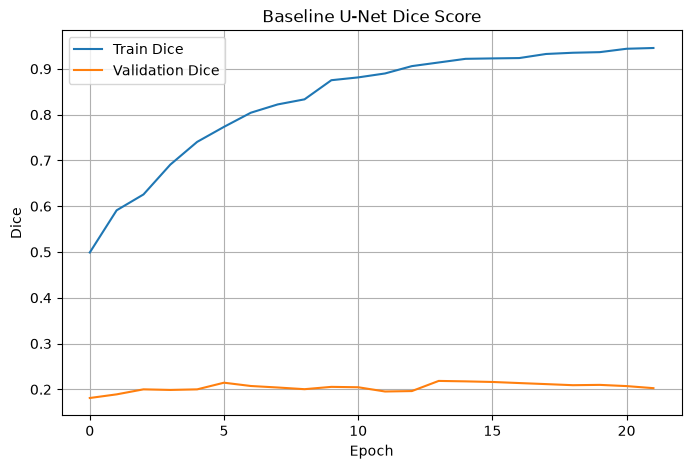

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["dice_coefficient"], label="Train Dice")
plt.plot(history.history["val_dice_coefficient"], label="Validation Dice")

plt.xlabel("Epoch")
plt.ylabel("Dice")
plt.title("Baseline U-Net Dice Score")
plt.legend()
plt.grid(True)

plt.show()

# Load the best U-Net

In [62]:
best_model = tf.keras.models.load_model(
    str(checkpoint_path),
    custom_objects={
        "dice_coefficient": dice_coefficient,
        "bce_dice_loss": bce_dice_loss
    }
)

print("Best U-Net loaded successfully.")

Best U-Net loaded successfully.


/home/vivek_chauhan/tf-env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_2', because it has 94 variables whereas the saved optimizer has 98 variables. 
  saveable.load_own_variables(store)


### Evaluate on the TEST set

This is important.

We have:

91 volumes → Training
19 volumes → Validation
21 volumes → Test

The 21 test volumes have not been used for training, so we use them now for the final U-Net evaluation.

We'll calculate:

Dice
IoU
Precision
Recall
Pixel Accuracy

# Define evaluation metrics

In [63]:
import numpy as np
import tensorflow as tf


def calculate_metrics(y_true, y_pred, threshold=0.5, smooth=1e-6):
    """
    Calculate segmentation metrics for one batch/image.
    """

    y_true = np.asarray(y_true).astype(np.float32)
    y_pred = (np.asarray(y_pred) >= threshold).astype(np.float32)

    # Flatten
    y_true = y_true.reshape(-1)
    y_pred = y_pred.reshape(-1)

    # Confusion values
    tp = np.sum(y_true * y_pred)
    tn = np.sum((1 - y_true) * (1 - y_pred))
    fp = np.sum((1 - y_true) * y_pred)
    fn = np.sum(y_true * (1 - y_pred))

    # Dice
    dice = (2 * tp + smooth) / (
        2 * tp + fp + fn + smooth
    )

    # IoU
    iou = (tp + smooth) / (
        tp + fp + fn + smooth
    )

    # Precision
    precision = (tp + smooth) / (
        tp + fp + smooth
    )

    # Recall
    recall = (tp + smooth) / (
        tp + fn + smooth
    )

    # Pixel accuracy
    accuracy = (tp + tn + smooth) / (
        tp + tn + fp + fn + smooth
    )

    return dice, iou, precision, recall, accuracy

# Evaluate U-Net on the test set

In [64]:
all_dice = []
all_iou = []
all_precision = []
all_recall = []
all_accuracy = []

for images, masks in test_dataset:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    batch_size = images.shape[0]

    for i in range(batch_size):

        dice, iou, precision, recall, accuracy = calculate_metrics(
            masks[i].numpy(),
            predictions[i]
        )

        all_dice.append(dice)
        all_iou.append(iou)
        all_precision.append(precision)
        all_recall.append(recall)
        all_accuracy.append(accuracy)


print("Test set evaluation completed.")

Test set evaluation completed.


# Calculate final U-Net numbers

In [65]:
baseline_results = {
    "Model": "U-Net",
    "Dice": np.mean(all_dice),
    "IoU": np.mean(all_iou),
    "Precision": np.mean(all_precision),
    "Recall": np.mean(all_recall),
    "Pixel Accuracy": np.mean(all_accuracy)
}

print("\n===== U-NET BASELINE RESULTS =====")

for metric, value in baseline_results.items():

    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.4f}")


===== U-NET BASELINE RESULTS =====
Model: U-Net
Dice: 0.8054
IoU: 0.7870
Precision: 0.8727
Recall: 0.8680
Pixel Accuracy: 0.9909


# Convert results into a table

In [66]:
import pandas as pd

baseline_df = pd.DataFrame([baseline_results])

baseline_df

,Model,Dice,IoU,Precision,Recall,Pixel Accuracy
0,U-Net,0.805355,0.786978,0.872667,0.867998,0.990871


# check all the images ->how many images were empty in each case 

In [68]:
import tensorflow as tf
import numpy as np

def get_empty_percentage(df):
    empty = 0

    for path in df["mask_path"]:
        mask = tf.io.read_file(path)
        mask = tf.image.decode_png(mask, channels=1)

        if tf.reduce_max(mask).numpy() == 0:
            empty += 1

    return 100 * empty / len(df)


print("Train empty %:", get_empty_percentage(train_df))
print("Validation empty %:", get_empty_percentage(val_df))
print("Test empty %:", get_empty_percentage(test_df))

Train empty %: 67.01363510346044
Validation empty %: 68.34821428571429
Test empty %: 67.61323867613238


# Save the baseline result

In [69]:
from pathlib import Path

RESULTS_DIR = Path(
    "/mnt/c/liverCTSegmentation/outputs/results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

baseline_df.to_csv(
    RESULTS_DIR / "unet_baseline_results.csv",
    index=False
)

print(
    "Baseline results saved to:",
    RESULTS_DIR / "unet_baseline_results.csv"
)

Baseline results saved to: /mnt/c/liverCTSegmentation/outputs/results/unet_baseline_results.csv


# Visualize U-Net predictions

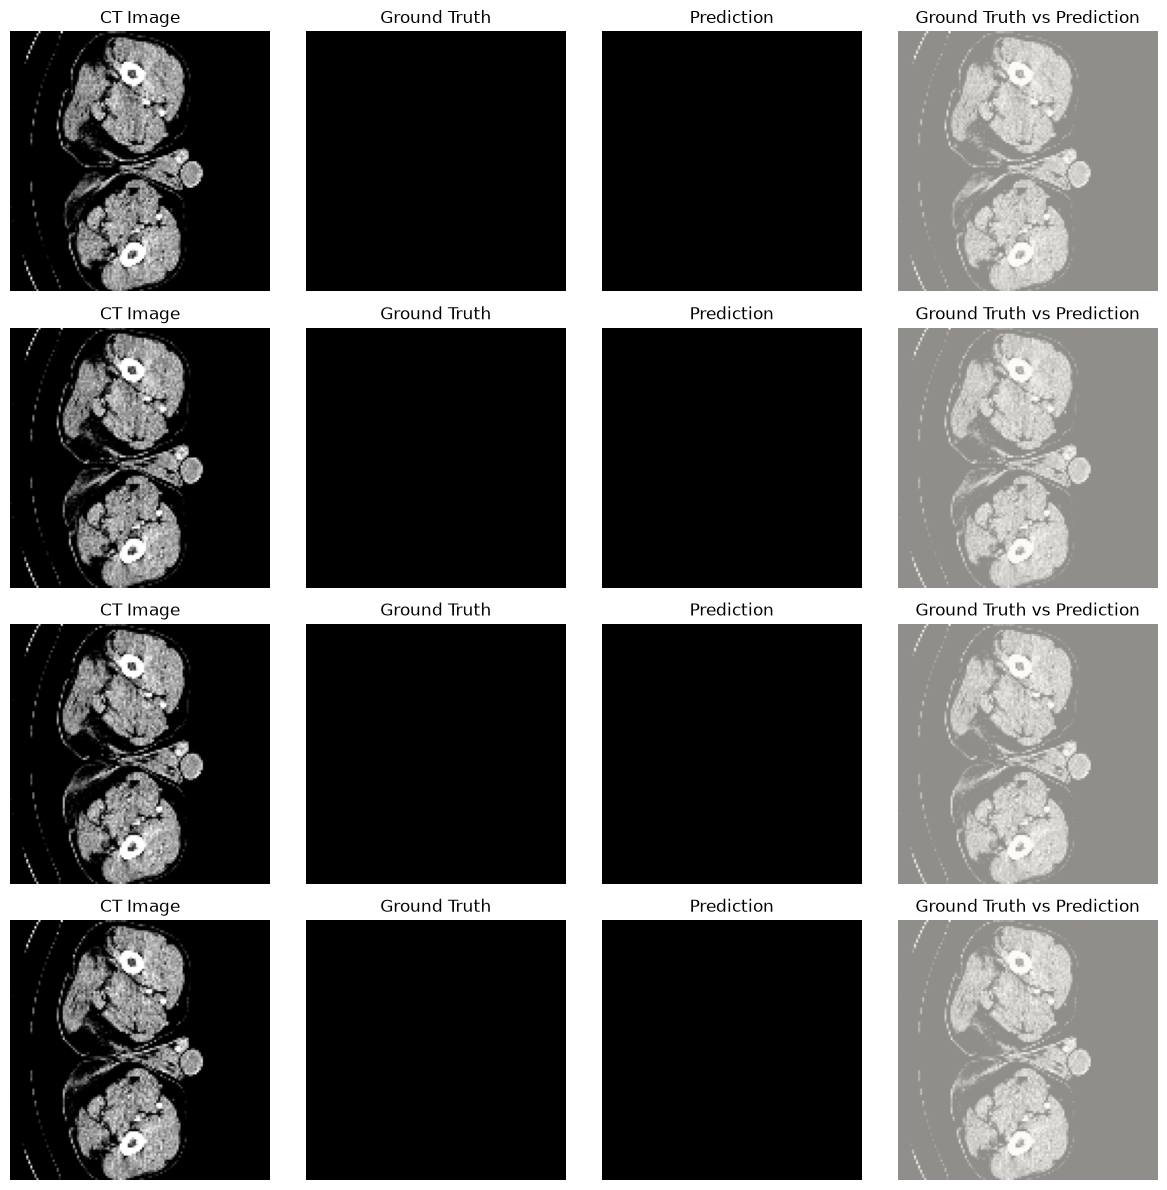

In [71]:
import matplotlib.pyplot as plt
import numpy as np

# Take one batch from the test set
test_images, test_masks = next(iter(test_dataset))

# Predict
test_predictions = best_model.predict(
    test_images,
    verbose=0
)

# Select first 4 samples
num_samples = 4

fig, axes = plt.subplots(
    num_samples,
    4,
    figsize=(12, 3 * num_samples)
)

for i in range(num_samples):

    image = test_images[i].numpy().squeeze()
    true_mask = test_masks[i].numpy().squeeze()
    pred_mask = (test_predictions[i].squeeze() >= 0.5).astype(np.float32)

    # Original CT
    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title("CT Image")
    axes[i, 0].axis("off")

    # Ground truth
    axes[i, 1].imshow(true_mask, cmap="gray")
    axes[i, 1].set_title("Ground Truth")
    axes[i, 1].axis("off")

    # Prediction
    axes[i, 2].imshow(pred_mask, cmap="gray")
    axes[i, 2].set_title("Prediction")
    axes[i, 2].axis("off")

    # Overlay
    axes[i, 3].imshow(image, cmap="gray")
    axes[i, 3].imshow(
        true_mask,
        alpha=0.35,
        cmap="Greens"
    )
    axes[i, 3].imshow(
        pred_mask,
        alpha=0.35,
        cmap="Reds"
    )
    axes[i, 3].set_title("Ground Truth vs Prediction")
    axes[i, 3].axis("off")

plt.tight_layout()
plt.show()

# Instead of taking the first 4 test samples, find samples where the ground-truth mask actually contains liver

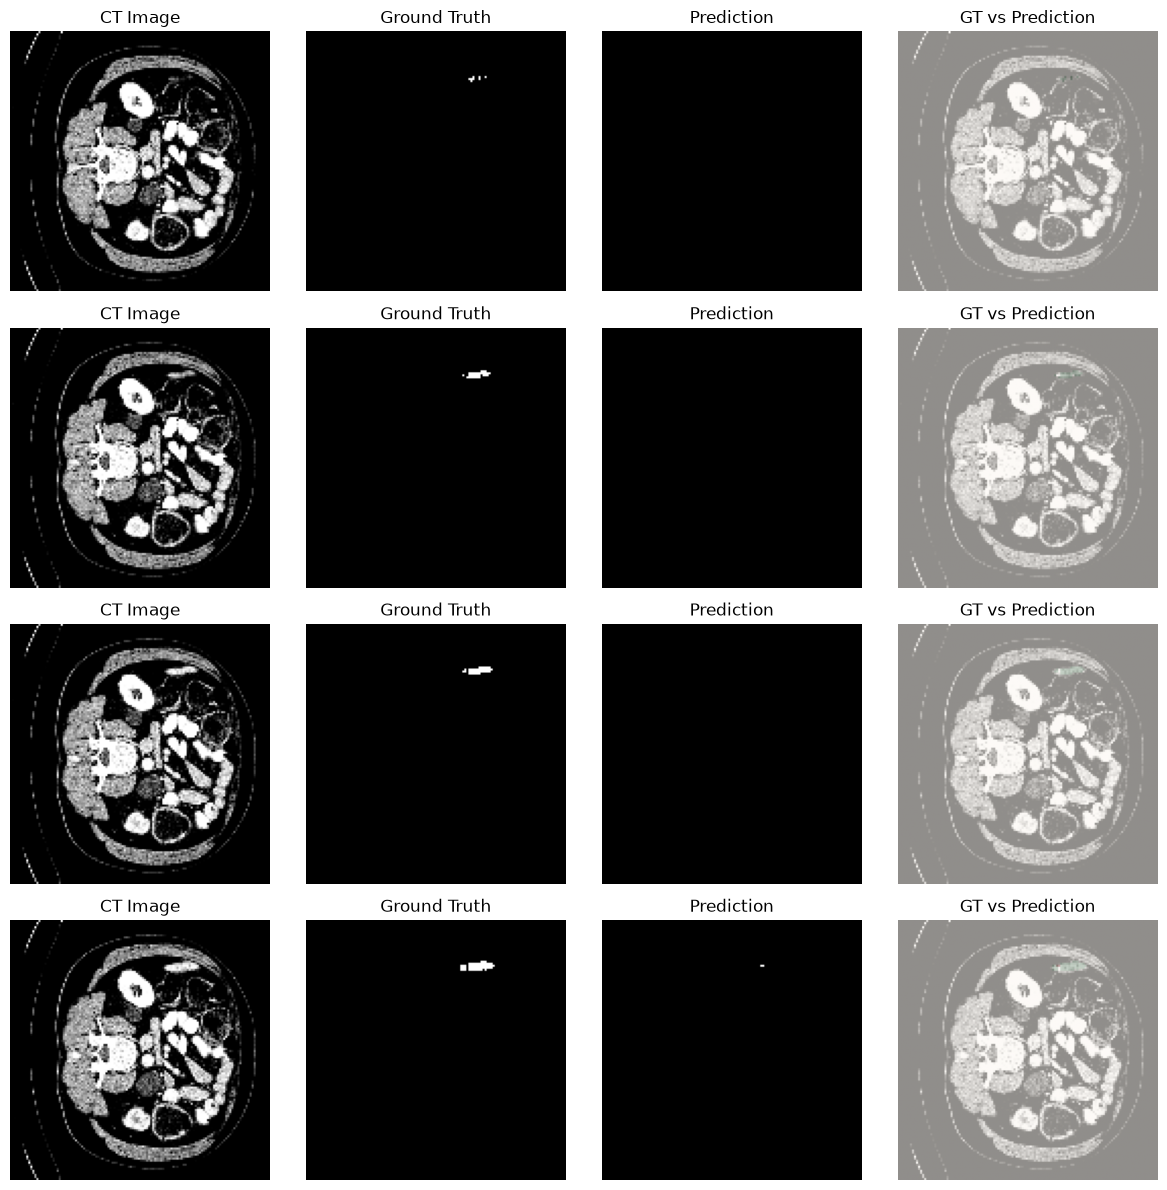

In [72]:
import matplotlib.pyplot as plt
import numpy as np

# Find test samples containing liver
selected_images = []
selected_masks = []
selected_predictions = []

for images, masks in test_dataset:
    predictions = best_model.predict(images, verbose=0)

    for i in range(images.shape[0]):
        mask = masks[i].numpy().squeeze()

        # Select only non-empty masks
        if np.sum(mask) > 0:
            selected_images.append(images[i].numpy().squeeze())
            selected_masks.append(mask)
            selected_predictions.append(
                predictions[i].squeeze()
            )

        if len(selected_images) >= 4:
            break

    if len(selected_images) >= 4:
        break


# Plot
fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i in range(4):

    image = selected_images[i]
    true_mask = selected_masks[i]
    pred_prob = selected_predictions[i]
    pred_mask = (pred_prob >= 0.5).astype(np.float32)

    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title("CT Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(true_mask, cmap="gray")
    axes[i, 1].set_title("Ground Truth")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(pred_mask, cmap="gray")
    axes[i, 2].set_title("Prediction")
    axes[i, 2].axis("off")

    axes[i, 3].imshow(image, cmap="gray")
    axes[i, 3].imshow(true_mask, alpha=0.35, cmap="Greens")
    axes[i, 3].imshow(pred_mask, alpha=0.35, cmap="Reds")
    axes[i, 3].set_title("GT vs Prediction")
    axes[i, 3].axis("off")

plt.tight_layout()
plt.show()

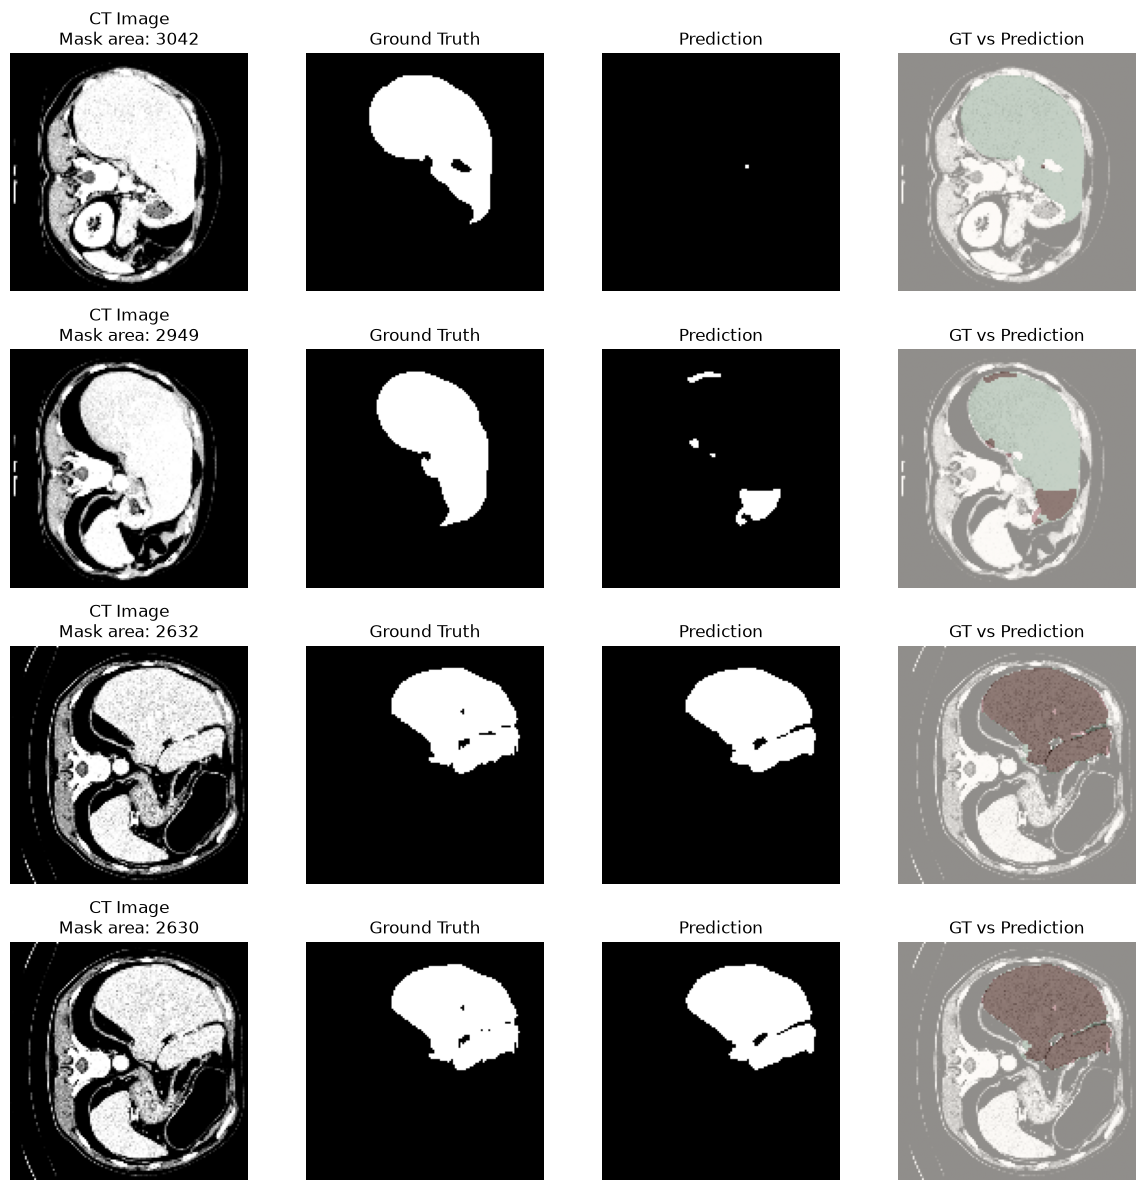

In [76]:
import matplotlib.pyplot as plt
import numpy as np

# Collect candidate non-empty samples with their mask area
candidates = []

for images, masks in test_dataset:
    predictions = best_model.predict(images, verbose=0)

    for i in range(images.shape[0]):
        image = images[i].numpy().squeeze()
        mask = masks[i].numpy().squeeze()
        prediction = predictions[i].squeeze()

        mask_area = np.sum(mask)

        if mask_area > 0:
            candidates.append(
                (mask_area, image, mask, prediction)
            )

# Sort by ground-truth liver area
candidates.sort(key=lambda x: x[0], reverse=True)

# Select 4 slices with large liver regions
selected = candidates[:4]

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i, (area, image, true_mask, pred_prob) in enumerate(selected):

    pred_mask = (pred_prob >= 0.5).astype(np.float32)

    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title(f"CT Image\nMask area: {int(area)}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(true_mask, cmap="gray")
    axes[i, 1].set_title("Ground Truth")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(pred_mask, cmap="gray")
    axes[i, 2].set_title("Prediction")
    axes[i, 2].axis("off")

    axes[i, 3].imshow(image, cmap="gray")
    axes[i, 3].imshow(true_mask, alpha=0.35, cmap="Greens")
    axes[i, 3].imshow(pred_mask, alpha=0.35, cmap="Reds")
    axes[i, 3].set_title("GT vs Prediction")
    axes[i, 3].axis("off")

plt.tight_layout()
plt.show()

In [77]:
# diagnostic evaluation

In [78]:
import numpy as np

nonempty_dice = []
nonempty_iou = []
nonempty_precision = []
nonempty_recall = []

empty_dice = []

for images, masks in test_dataset:

    predictions = best_model.predict(images, verbose=0)

    for i in range(images.shape[0]):

        true_mask = masks[i].numpy()
        pred_mask = predictions[i]

        dice, iou, precision, recall, accuracy = calculate_metrics(
            true_mask,
            pred_mask,
            threshold=0.5
        )

        # Ground-truth liver area
        liver_pixels = np.sum(true_mask)

        if liver_pixels > 0:

            nonempty_dice.append(dice)
            nonempty_iou.append(iou)
            nonempty_precision.append(precision)
            nonempty_recall.append(recall)

        else:

            empty_dice.append(dice)


print("===================================")
print("NON-EMPTY TEST SLICES")
print("===================================")

print("Number of non-empty slices:", len(nonempty_dice))
print("Dice:", np.mean(nonempty_dice))
print("IoU:", np.mean(nonempty_iou))
print("Precision:", np.mean(nonempty_precision))
print("Recall:", np.mean(nonempty_recall))

print("\n===================================")
print("EMPTY TEST SLICES")
print("===================================")

print("Number of empty slices:", len(empty_dice))
print("Dice:", np.mean(empty_dice))

NON-EMPTY TEST SLICES
Number of non-empty slices: 3216
Dice: 0.47274584
IoU: 0.4155981
Precision: 0.68207324
Recall: 0.5895044

EMPTY TEST SLICES
Number of empty slices: 6785
Dice: 0.9630066


In [79]:
# check your validation set with the same external metric.

In [80]:
val_nonempty_dice = []
val_nonempty_iou = []
val_nonempty_precision = []
val_nonempty_recall = []

val_empty_dice = []

for images, masks in val_dataset:

    predictions = best_model.predict(images, verbose=0)

    for i in range(images.shape[0]):

        true_mask = masks[i].numpy()
        pred_mask = predictions[i]

        dice, iou, precision, recall, accuracy = calculate_metrics(
            true_mask,
            pred_mask,
            threshold=0.5
        )

        liver_pixels = np.sum(true_mask)

        if liver_pixels > 0:

            val_nonempty_dice.append(dice)
            val_nonempty_iou.append(iou)
            val_nonempty_precision.append(precision)
            val_nonempty_recall.append(recall)

        else:

            val_empty_dice.append(dice)


print("===================================")
print("NON-EMPTY VALIDATION SLICES")
print("===================================")

print("Number:", len(val_nonempty_dice))
print("Dice:", np.mean(val_nonempty_dice))
print("IoU:", np.mean(val_nonempty_iou))
print("Precision:", np.mean(val_nonempty_precision))
print("Recall:", np.mean(val_nonempty_recall))

print("\n===================================")
print("EMPTY VALIDATION SLICES")
print("===================================")

print("Number:", len(val_empty_dice))
print("Dice:", np.mean(val_empty_dice))

NON-EMPTY VALIDATION SLICES
Number: 2819
Dice: 0.63033116
IoU: 0.5678302
Precision: 0.76118207
Recall: 0.71389264

EMPTY VALIDATION SLICES
Number: 6141
Dice: 0.9130435


# compare:

train
validation
test

for non-empty percentage and liver area.

In [81]:
import numpy as np

def dataset_mask_statistics(df, name):

    nonempty_areas = []
    empty_count = 0
    total_count = 0

    for mask_path in df["mask_path"]:

        mask = tf.io.read_file(mask_path)
        mask = tf.image.decode_png(mask, channels=1)
        mask = tf.cast(mask > 127, tf.float32)

        area = float(tf.reduce_sum(mask).numpy())

        total_count += 1

        if area > 0:
            nonempty_areas.append(area)
        else:
            empty_count += 1

    nonempty_areas = np.array(nonempty_areas)

    print(f"\n===== {name} =====")
    print("Total slices:", total_count)
    print("Empty slices:", empty_count)
    print(
        "Non-empty slices:",
        total_count - empty_count
    )
    print(
        "Non-empty %:",
        100 * (total_count - empty_count) / total_count
    )

    if len(nonempty_areas) > 0:
        print(
            "Mean liver area:",
            np.mean(nonempty_areas)
        )
        print(
            "Median liver area:",
            np.median(nonempty_areas)
        )
        print(
            "Max liver area:",
            np.max(nonempty_areas)
        )


dataset_mask_statistics(train_df, "TRAIN")
dataset_mask_statistics(val_df, "VALIDATION")
dataset_mask_statistics(test_df, "TEST")


===== TRAIN =====
Total slices: 39677
Empty slices: 26589
Non-empty slices: 13088
Non-empty %: 32.986364896539556
Mean liver area: 10228.654110635696
Median liver area: 5114.0
Max liver area: 52405.0

===== VALIDATION =====
Total slices: 8960
Empty slices: 6124
Non-empty slices: 2836
Non-empty %: 31.651785714285715
Mean liver area: 11791.453808180537
Median liver area: 7054.5
Max liver area: 48544.0

===== TEST =====
Total slices: 10001
Empty slices: 6762
Non-empty slices: 3239
Non-empty %: 32.38676132386761
Mean liver area: 9302.874652670578
Median liver area: 4620.0
Max liver area: 48739.0


# our earlier full-dataset audit reported maximum liver area around 3,279 pixels, while this new calculation reports maximum areas around 48,000–52,000 pixels.

That's a major discrepancy.

This is important.

It suggests the two analyses may have been using different mask representations/resolutions or different preprocessing stages.

Before we retrain anything, I want to verify this because your mask statistics should be consistent.

Run this very small check on one mask:

In [82]:
sample_mask_path = train_df.iloc[0]["mask_path"]

mask = tf.io.read_file(sample_mask_path)
mask = tf.image.decode_png(mask, channels=1)

print("Original mask shape:", mask.shape)
print("Original mask dtype:", mask.dtype)
print("Original mask min:", tf.reduce_min(mask).numpy())
print("Original mask max:", tf.reduce_max(mask).numpy())
print("Original mask unique values:", np.unique(mask.numpy())[:20])

Original mask shape: (512, 512, 1)
Original mask dtype: <dtype: 'uint8'>
Original mask min: 0
Original mask max: 0
Original mask unique values: [0]


# verify with an actual liver-containing mask

In [83]:
# Find the first non-empty mask
for idx in range(len(train_df)):

    mask_path = train_df.iloc[idx]["mask_path"]

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)

    area = tf.reduce_sum(tf.cast(mask > 0, tf.int32)).numpy()

    if area > 0:
        print("Found non-empty mask")
        print("Index:", idx)
        print("Path:", mask_path)
        print("Shape:", mask.shape)
        print("Dtype:", mask.dtype)
        print("Min:", tf.reduce_min(mask).numpy())
        print("Max:", tf.reduce_max(mask).numpy())
        print("Unique values:", np.unique(mask.numpy())[:20])
        print("Liver area:", area)
        break

Found non-empty mask
Index: 45
Path: /mnt/c/Users/vivek chauhan/Desktop/dsa babbar/Videos/archive (26)/last_dataset/masks/Volume-001-045.png
Shape: (512, 512, 1)
Dtype: <dtype: 'uint8'>
Min: 0
Max: 255
Unique values: [  0 255]
Liver area: 8


# We have enough evidence that the dataset itself isn't the immediate problem.

The next thing I want to investigate is why validation Dice = 0.63 but test Dice = 0.47 on liver-containing slices.

We'll inspect the distribution of liver area in the three splits, particularly the median and percentiles.

In [84]:
def get_nonempty_areas(df):

    areas = []

    for mask_path in df["mask_path"]:

        mask = tf.io.read_file(mask_path)
        mask = tf.image.decode_png(mask, channels=1)

        area = tf.reduce_sum(
            tf.cast(mask > 0, tf.int32)
        ).numpy()

        if area > 0:
            areas.append(area)

    return np.array(areas)


train_areas = get_nonempty_areas(train_df)
val_areas = get_nonempty_areas(val_df)
test_areas = get_nonempty_areas(test_df)


for name, areas in [
    ("TRAIN", train_areas),
    ("VALIDATION", val_areas),
    ("TEST", test_areas)
]:

    print(f"\n===== {name} =====")

    print("Count:", len(areas))
    print("Min:", np.min(areas))
    print("25th percentile:", np.percentile(areas, 25))
    print("Median:", np.median(areas))
    print("75th percentile:", np.percentile(areas, 75))
    print("90th percentile:", np.percentile(areas, 90))
    print("95th percentile:", np.percentile(areas, 95))
    print("Max:", np.max(areas))


===== TRAIN =====
Count: 13088
Min: 1
25th percentile: 6318.5
Median: 16858.5
75th percentile: 29051.5
90th percentile: 37704.9
95th percentile: 41990.5
Max: 56540

===== VALIDATION =====
Count: 2836
Min: 2
25th percentile: 5748.75
Median: 16473.0
75th percentile: 28086.25
90th percentile: 38955.5
95th percentile: 42774.25
Max: 59519

===== TEST =====
Count: 3239
Min: 2
25th percentile: 5924.0
Median: 16190.0
75th percentile: 27896.5
90th percentile: 36269.200000000004
95th percentile: 38366.2
Max: 50651


# Save the visualization

In [ ]:
FIGURE_DIR = Path(
    r"C:\\liverCTSegmentation\\outputs\\figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("CT Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(true_mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_mask_binary, cmap="gray")
plt.title("U-Net Prediction")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "unet_prediction_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:",
    FIGURE_DIR / "unet_prediction_example.png"
)

In [85]:
# ============================================================
# CHECK ALL KERAS MODELS CURRENTLY IN MEMORY
# ============================================================

import tensorflow as tf

print("=" * 60)
print("KERAS MODELS CURRENTLY IN MEMORY")
print("=" * 60)

found = False

# Take a snapshot so globals() cannot change during iteration
objects = list(globals().items())

for name, obj in objects:
    try:
        if isinstance(obj, tf.keras.Model):
            found = True

            print("\nVariable:", name)
            print("Model name:", obj.name)
            print("Parameters:", obj.count_params())
            print("Input shape:", obj.input_shape)
            print("Output shape:", obj.output_shape)

    except Exception:
        pass

if not found:
    print("\nNo Keras model objects are currently in memory.")

KERAS MODELS CURRENTLY IN MEMORY

Variable: model
Model name: Baseline_UNet
Parameters: 31030593
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)

Variable: best_model
Model name: Baseline_UNet
Parameters: 31030593
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)


In [86]:
# ============================================================
# SAVE IN-MEMORY BEST BASELINE U-NET
# ============================================================

import os
import tensorflow as tf

save_dir = "/mnt/c/liverCTSegmentation/outputs/checkpoints"
os.makedirs(save_dir, exist_ok=True)

new_checkpoint = os.path.join(
    save_dir,
    "baseline_unet_best_recovered.keras"
)

print("=" * 60)
print("SAVING RECOVERED BASELINE U-NET")
print("=" * 60)

print("Model:", best_model.name)
print("Parameters:", best_model.count_params())
print("Input shape:", best_model.input_shape)
print("Output shape:", best_model.output_shape)

best_model.save(new_checkpoint)

print("\nSaved to:")
print(new_checkpoint)

# ------------------------------------------------------------
# VERIFY THE NEW CHECKPOINT
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("VERIFYING CHECKPOINT")
print("=" * 60)

print("File exists:", os.path.exists(new_checkpoint))

if os.path.exists(new_checkpoint):
    size_mb = os.path.getsize(new_checkpoint) / (1024 ** 2)
    print(f"File size: {size_mb:.2f} MB")

    # Try loading it back
    recovered_model = tf.keras.models.load_model(
        new_checkpoint,
        custom_objects={
            "dice_coefficient": dice_coefficient,
            "dice_loss": dice_loss,
            "bce_dice_loss": bce_dice_loss
        },
        compile=False
    )

    print("\nCheckpoint loaded successfully!")
    print("Loaded model:", recovered_model.name)
    print("Parameters:", recovered_model.count_params())
    print("Input shape:", recovered_model.input_shape)
    print("Output shape:", recovered_model.output_shape)

    print("\n" + "=" * 60)
    print("BASELINE CHECKPOINT RECOVERY SUCCESSFUL")
    print("=" * 60)

SAVING RECOVERED BASELINE U-NET
Model: Baseline_UNet
Parameters: 31030593
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)

Saved to:
/mnt/c/liverCTSegmentation/outputs/checkpoints/baseline_unet_best_recovered.keras

VERIFYING CHECKPOINT
File exists: True
File size: 355.27 MB

Checkpoint loaded successfully!
Loaded model: Baseline_UNet
Parameters: 31030593
Input shape: (None, 128, 128, 1)
Output shape: (None, 128, 128, 1)

BASELINE CHECKPOINT RECOVERY SUCCESSFUL
